# 02 · EDA Bagian 6 — Sintesis: Dari Temuan ke Rencana Fitur & Validasi

Bagian ini menggabungkan **semua sumber** dalam satu tabel fitur (fungsi di `features.py`), lalu menjawab:

| # | Pertanyaan |
|---|---|
| Q1 | Fitur apa yang paling kuat lintas sumber, dan seberapa luas cakupannya? |
| Q2 | Bagaimana KS bertambah seiring setiap sumber ditambahkan? |
| Q3 | Berapa kontribusi **unik** tiap sumber (apa yang hilang kalau sumber itu dibuang)? |
| Q4 | Seberapa banyak fitur yang redundan? Apakah set fitur ramping cukup? |
| Q5 | Apakah satu model cukup untuk semua segmen? |
| Q6 | Interaksi apa yang paling penting? |
| Q7 | Seberapa stabil KS validasi, dan berapa noise yang wajar di leaderboard? |
| Q8 | Daftar prioritas fitur, ide fitur baru, dan checklist kebocoran untuk tahap feature engineering. |

> Notebook ini melatih ~18 model LightGBM (5-fold), jadi butuh beberapa belas menit. Angka di bawah berasal dari run dengan file e-commerce **sampling**. Dengan file penuh, KS model lengkap Anda sedikit lebih tinggi (Bagian 5: 0,518 vs 0,507).

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F
from sklearn.model_selection import StratifiedKFold

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

tr = E.load("train_applications")
cp = E.load("customer_profiles")
CUT = tr.select("application_id", "customer_id", pl.col("decision_datetime").alias("cutoff"))
cut2 = CUT.select("customer_id", "cutoff")
ec = E.lazy("ecommerce_transactions")

df = (tr.join(cp, on="customer_id", how="left")
        .join(F.prev_app_features(E.load("previous_applications"), cut2), on="customer_id", how="left")
        .join(F.loan_features(E.load("previous_applications"), E.load("repayment_history"), cut2), on="customer_id", how="left")
        .join(F.repayment_features(E.load("repayment_history"), cut2), on="customer_id", how="left")
        .join(F.bureau_features(E.load("bureau_observations"), CUT, income=cp.select("customer_id", "declared_monthly_income")), on="customer_id", how="left")
        .join(F.account_features(E.load("account_behavior"), cut2), on="customer_id", how="left")
        .join(F.ecommerce_features(ec, cut2, cat_medians=F.ecommerce_category_medians(ec)), on="customer_id", how="left")
        .with_columns(dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
                      total_dti=(pl.col("proposed_monthly_installment") + pl.col("ln_active_installment").fill_null(0))
                                / pl.col("declared_monthly_income"),
                      segment=pl.when(pl.col("pa_n").is_null()).then(pl.lit("A. tanpa riwayat"))
                                .when(pl.col("rp_n_inst").is_null()).then(pl.lit("B. ada pengajuan, belum ada cicilan"))
                                .otherwise(pl.lit("C. ada riwayat cicilan"))))

APP = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose", "age", "region",
       "employment_type", "employment_tenure_months", "declared_monthly_income", "dependents", "housing_status", "dti"]
INTERNAL = [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"] + ["total_dti", "segment"]
BUREAU = [c for c in df.columns if c.startswith("bu_")]
ACCOUNT = [c for c in df.columns if c.startswith("ac_")]
ECOM = [c for c in df.columns if c.startswith("ec_")]
PREMIUM = [c for c in ECOM if "premium" in c]
SOURCES = {"aplikasi & profil": APP, "riwayat internal": INTERNAL, "biro": BUREAU, "rekening": ACCOUNT, "e-commerce": ECOM}
SRC_OF = {f: s for s, fs in SOURCES.items() for f in fs}
SRC_COLOR = dict(zip(SOURCES, E.SERIES[:5]))
CATS = ["loan_purpose", "region", "employment_type", "housing_status", "segment"]
FULL = APP + INTERNAL + BUREAU + ACCOUNT + ECOM
y = df["target"].to_numpy()
SEG = df["segment"].to_numpy()

def run(feats, data=df, seed=42):
    oof, ks, auc, imp = E.cv_lgb(data, feats, cat_features=[c for c in CATS if c in feats], seed=seed)
    seg = data["segment"].to_numpy(); yy = data["target"].to_numpy()
    out = dict(n_features=len(feats), ks=round(ks, 4), auc=round(auc, 4))
    for s in ("A", "B", "C"):
        m = np.array([v.startswith(s) for v in seg])
        if m.sum() > 100 and len(set(yy[m])) > 1:
            out[f"ks_{s}"] = round(E.ks_stat(yy[m], oof[m]), 4)
    return out, oof, imp

print(f"{df.height:,} baris | {len(FULL)} fitur: " + ", ".join(f"{k} {len(v)}" for k, v in SOURCES.items()))

70,000 baris | 180 fitur: aplikasi & profil 12, riwayat internal 47, biro 33, rekening 39, e-commerce 49


## Q1 · Peta sinyal lintas sumber

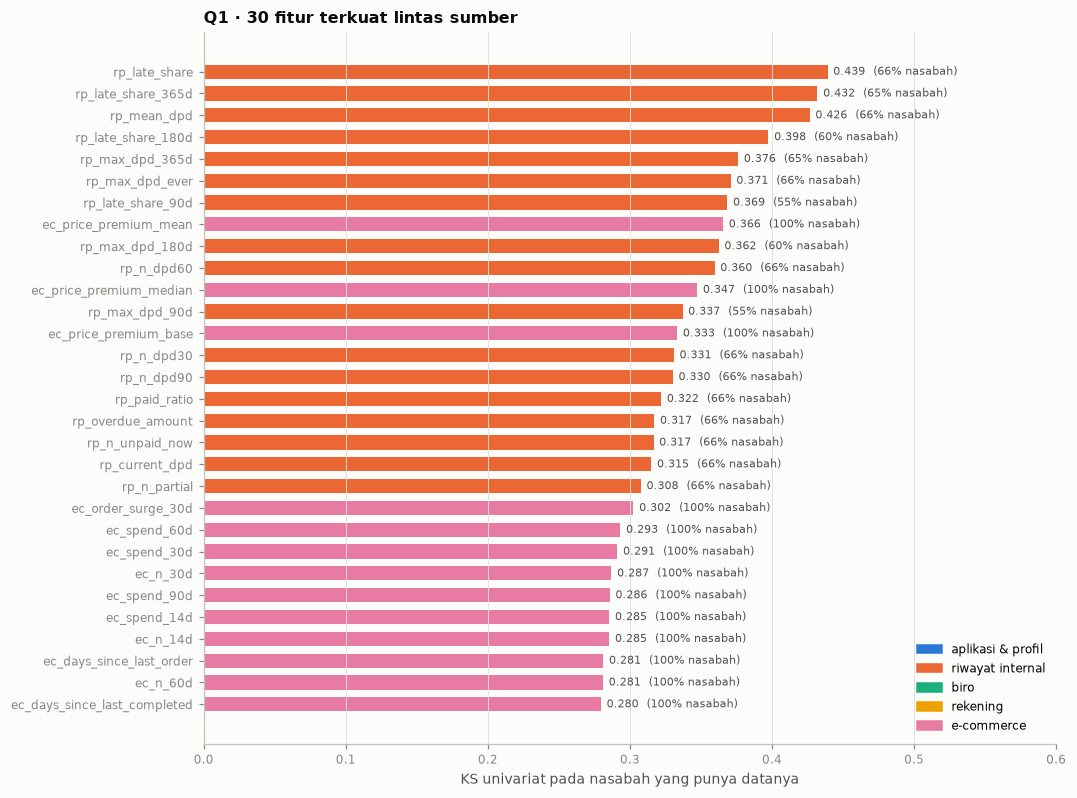

source,n_features,best_ks,n_ks_gt_0_10,n_noise,coverage_pct
str,u32,f64,u32,u32,f64
"""riwayat internal""",47,0.4391,21,8,66.5
"""e-commerce""",49,0.3656,27,12,100.0
"""biro""",33,0.253,12,5,100.0
"""aplikasi & profil""",12,0.2301,1,7,100.0
"""rekening""",39,0.1412,9,12,70.0


In [2]:
rows = []
for f in FULL:
    s = df[f]
    x = s.cast(pl.String).to_numpy() if s.dtype in (pl.String, pl.Categorical, pl.Boolean) else s.cast(pl.Float64).to_numpy()
    nn = ~s.is_null().to_numpy()
    rows.append(dict(feature=f, source=SRC_OF[f], coverage_pct=round(nn.mean() * 100, 1),
                     ks_all=round(E.ks_stat(y, x), 4), ks_covered=round(E.ks_stat(y[nn], x[nn]), 4) if nn.sum() > 1000 else None))
sig = pl.DataFrame(rows).sort("ks_covered", descending=True, nulls_last=True)
top = sig.head(30)
fig, ax = plt.subplots(figsize=(10, 8.4))
t = top.reverse()
ax.barh(t["feature"].to_list(), t["ks_covered"].to_list(), color=[SRC_COLOR[s] for s in t["source"]], height=0.65)
for i, (k, cov) in enumerate(zip(t["ks_covered"].to_list(), t["coverage_pct"].to_list())):
    ax.text(k + 0.004, i, f"{k:.3f}  ({cov:.0f}% nasabah)", va="center", fontsize=7.5, color=E.INK2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in SRC_COLOR.items()], loc="lower right", fontsize=8)
ax.set_xlim(0, 0.6); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("KS univariat pada nasabah yang punya datanya")
ax.set_title("Q1 · 30 fitur terkuat lintas sumber")
plt.show()
display(sig.group_by("source").agg(n_features=pl.len(), best_ks=pl.col("ks_covered").max(),
                                   n_ks_gt_0_10=(pl.col("ks_covered") > 0.10).sum(), n_noise=(pl.col("ks_covered") < 0.022).sum(),
                                   coverage_pct=pl.col("coverage_pct").median()).sort("best_ks", descending=True))

**Jawaban Q1.**
- Sinyal terkuat secara absolut adalah **riwayat bayar internal** (porsi cicilan telat, KS ~0,44), tetapi hanya tersedia untuk ~66% nasabah.
- Sinyal terkuat yang tersedia untuk **100% nasabah** adalah **price premium e-commerce** (~0,34), disusul keterbaruan/volume belanja 30 hari (~0,26) dan skor biro (~0,25).
- Kepadatan sinyal per sumber berbeda jauh. E-commerce punya ~27 fitur dengan KS > 0,10, riwayat internal ~21, biro ~12, rekening ~9, dan aplikasi hanya 1 (suku bunga).
- Banyak fitur yang praktis noise, terutama di rekening, e-commerce (kategori, pembatalan), dan aplikasi/profil. Ini kandidat untuk dibuang di tahap feature engineering.

## Q2 · Perjalanan KS: menambahkan sumber satu per satu

step,n_features,ks,auc,ks_A,ks_B,ks_C
str,i64,f64,f64,f64,f64,f64
"""1. aplikasi & profil""",12,0.228,0.6455,0.1935,0.2367,0.243
"""2. + riwayat internal""",59,0.3959,0.776,0.1978,0.1989,0.4911
"""3. + biro""",92,0.4181,0.787,0.2487,0.2671,0.4945
"""4. + rekening""",131,0.4252,0.7907,0.2515,0.3471,0.5042
"""5. + e-commerce (LENGKAP)""",180,0.5162,0.8405,0.4877,0.5235,0.5286


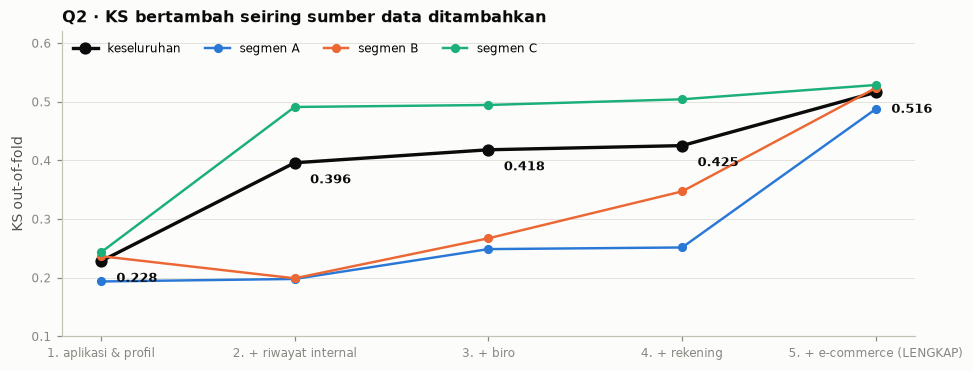

In [3]:
steps = [("1. aplikasi & profil", APP),
         ("2. + riwayat internal", APP + INTERNAL),
         ("3. + biro", APP + INTERNAL + BUREAU),
         ("4. + rekening", APP + INTERNAL + BUREAU + ACCOUNT),
         ("5. + e-commerce (LENGKAP)", FULL)]
prog, OOF, IMP = [], {}, {}
for name, feats in steps:
    r, oof, imp = run(feats)
    prog.append(dict(step=name, **r)); OOF[name] = oof; IMP[name] = imp
prog = pl.DataFrame(prog)
display(prog)
fig, ax = plt.subplots(figsize=(10, 3.6))
xs = np.arange(prog.height)
ax.plot(xs, prog["ks"].to_numpy(), color=E.INK, marker="o", ms=7, lw=2.2, label="keseluruhan")
for j, (s, lab) in enumerate([("ks_A", "segmen A"), ("ks_B", "segmen B"), ("ks_C", "segmen C")]):
    ax.plot(xs, prog[s].to_numpy(), color=E.SERIES[j], marker="o", ms=5, lw=1.6, label=lab)
for i, v in enumerate(prog["ks"].to_list()):
    ax.text(i + 0.08, v - 0.035, f"{v:.3f}", ha="left", fontsize=8.5, color=E.INK, fontweight="bold")
ax.set_xticks(xs); ax.set_xticklabels(prog["step"].to_list(), fontsize=8)
ax.set_ylim(0.1, 0.62); ax.set_ylabel("KS out-of-fold"); ax.legend(ncols=4, loc="upper left")
ax.set_title("Q2 · KS bertambah seiring sumber data ditambahkan")
plt.show()

**Jawaban Q2 — perjalanan KS sepanjang EDA:**

| Langkah | KS | Δ | Segmen A |
|---|---|---|---|
| aplikasi & profil | ~0,23 | | ~0,19 |
| + riwayat internal | ~0,40 | **+0,17** | ~0,20 |
| + biro | ~0,42 | +0,02 | ~0,25 |
| + rekening | ~0,425 | +0,007 | ~0,25 |
| + e-commerce | **~0,51** | **+0,08** | **~0,47** |

Dua lompatan besar datang dari **riwayat bayar** (mengangkat segmen C) dan **e-commerce** (mengangkat segmen A & B). Biro dan rekening hanya menambah sedikit.

## Q3 · Kontribusi UNIK tiap sumber (ablation)

Model lengkap dilatih ulang **tanpa** satu sumber. Penurunan KS = informasi yang **hanya** dimiliki sumber itu (tidak bisa digantikan sumber lain).

config,n_features,ks,auc,ks_A,ks_B,ks_C,delta_ks,delta_A,delta_C
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""lengkap""",180,0.5162,0.8405,0.4877,0.5235,0.5286,0.0,0.0,0.0
"""tanpa aplikasi & profil""",168,0.5143,0.8389,0.4882,0.5133,0.5252,-0.0019,0.0005,-0.0034
"""tanpa riwayat internal""",134,0.48,0.8194,0.4932,0.5232,0.472,-0.0362,0.0055,-0.0566
"""tanpa biro""",147,0.5057,0.8313,0.4592,0.4965,0.5255,-0.0105,-0.0285,-0.0031
"""tanpa rekening""",141,0.515,0.8401,0.4924,0.5173,0.5247,-0.0012,0.0047,-0.0039
"""tanpa e-commerce""",131,0.4252,0.7907,0.2515,0.3471,0.5042,-0.091,-0.2362,-0.0244
"""tanpa price premium saja""",176,0.5036,0.8331,0.4712,0.4779,0.5232,-0.0126,-0.0165,-0.0054


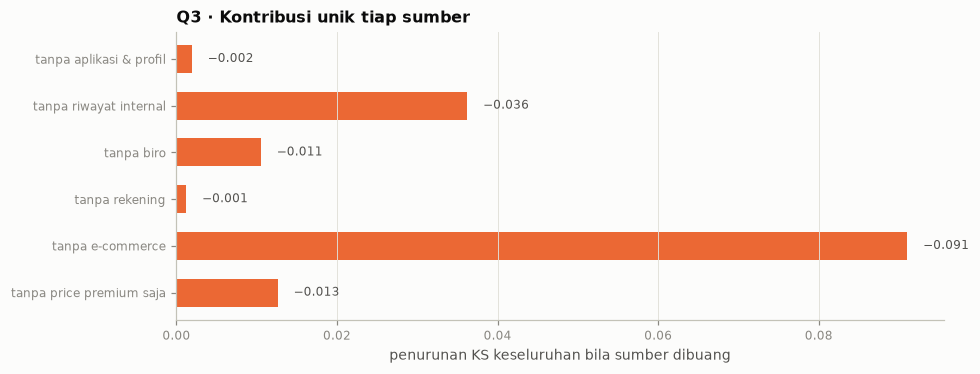

In [4]:
full_row = prog.filter(pl.col("step").str.contains("LENGKAP")).to_dicts()[0]
abl = [dict(config="lengkap", **{k: full_row[k] for k in ("n_features", "ks", "auc", "ks_A", "ks_B", "ks_C")})]
for name, drop in [("tanpa aplikasi & profil", APP), ("tanpa riwayat internal", [c for c in INTERNAL if c != "segment"]),
                   ("tanpa biro", BUREAU), ("tanpa rekening", ACCOUNT), ("tanpa e-commerce", ECOM),
                   ("tanpa price premium saja", PREMIUM)]:
    if name == "tanpa e-commerce":   # = langkah 4 di Q2, tidak perlu dilatih ulang
        r = {k: prog.filter(pl.col("step").str.starts_with("4."))[k][0] for k in ("n_features", "ks", "auc", "ks_A", "ks_B", "ks_C")}
    else:
        r, _, _ = run([f for f in FULL if f not in drop])
    abl.append(dict(config=name, **r))
abl = pl.DataFrame(abl).with_columns((pl.col("ks") - full_row["ks"]).round(4).alias("delta_ks"),
                                     (pl.col("ks_A") - full_row["ks_A"]).round(4).alias("delta_A"),
                                     (pl.col("ks_C") - full_row["ks_C"]).round(4).alias("delta_C"))
display(abl)
a2 = abl.filter(pl.col("config") != "lengkap")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(a2["config"].to_list()[::-1], (-a2["delta_ks"]).to_list()[::-1], color=E.SERIES[1], height=0.6)
for i, v in enumerate((-a2["delta_ks"]).to_list()[::-1]):
    ax.text(max(v, 0) + 0.002, i, f"−{v:.3f}" if v >= 0 else f"+{-v:.3f}", va="center", fontsize=8, color=E.INK2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("penurunan KS keseluruhan bila sumber dibuang"); ax.set_title("Q3 · Kontribusi unik tiap sumber")
plt.show()

**Jawaban Q3 — kontribusi unik (yang hilang bila sumber dibuang dari model lengkap):**
- **E-commerce: −0,080** (segmen A **−0,21**!). Sumber yang paling tak tergantikan.
- **Riwayat internal: −0,046** (segmen C −0,07).
- **Biro: −0,014** (segmen A −0,03), penting terutama untuk nasabah tanpa riwayat.
- **Price premium saja: −0,011** (segmen A −0,03). Satu kelompok fitur (4 kolom) setara kontribusi seluruh biro.
- **Aplikasi & profil: ≈ 0.** Suku bunga sepenuhnya tergantikan skor biro (Bagian 3), dan profil memang noise. Kolom ini tetap boleh masuk (murah), tapi tidak perlu direkayasa.
- **Rekening: ≈ 0** (+0,003, di dalam noise). Lonjakan pengeluaran rekening sudah tertangkap oleh lonjakan belanja e-commerce + riwayat bayar. Rekening menjadi prioritas terendah.

## Q4 · Redundansi & set fitur ramping

In [5]:
num = [f for f in FULL if df[f].dtype.is_numeric()]
sample = df.select(num).sample(20_000, seed=0).to_pandas()
cm = sample.corr(method="spearman").abs()
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(num) for b in num[i + 1:] if cm.loc[a, b] > 0.95]
print(f"{len(pairs)} pasangan fitur dengan |Spearman ρ| > 0,95, contoh:")
for a, b, r in sorted(pairs, key=lambda t: -t[2])[:12]:
    print(f"   {a:<32} ~ {b:<32} ρ={r:.3f}")
imp_full = IMP["5. + e-commerce (LENGKAP)"]
rk = []
for k in (20, 40, 80):
    feats = imp_full.head(k)["feature"].to_list()
    if "segment" not in feats:
        feats = feats + ["segment"]
    r, _, _ = run(feats)
    rk.append(dict(top_k=k, **r))
rk.append(dict(top_k=len(FULL), **{k: full_row[k] for k in ("n_features", "ks", "auc", "ks_A", "ks_B", "ks_C")}))
display(pl.DataFrame(rk))
imp_full.head(40).with_columns(pl.col("gain_pct").round(2), pl.col("feature").replace_strict(SRC_OF, default="-").alias("source"))

52 pasangan fitur dengan |Spearman ρ| > 0,95, contoh:
   pa_n_approved                    ~ ln_n                             ρ=1.000
   loan_amount                      ~ proposed_monthly_installment     ρ=1.000
   ac_avg_bal_3m                    ~ ac_avg_bal_6m                    ρ=0.996
   ac_avg_bal_3m                    ~ ac_min_bal_3m                    ρ=0.994
   ac_avg_bal_3m                    ~ ac_last_closing                  ρ=0.993
   ec_spend_surge_30d               ~ ec_spend_30d_share_of_year       ρ=0.992
   bu_hist_score_mean               ~ bu_all_score_mean                ρ=0.991
   ac_min_bal_3m                    ~ ac_avg_bal_6m                    ρ=0.991
   pa_n_cancelled                   ~ pa_cancel_share                  ρ=0.989
   ac_min_bal_3m                    ~ ac_last_closing                  ρ=0.988
   bu_hist_n                        ~ bu_all_n                         ρ=0.987
   rp_n_unpaid_now                  ~ rp_overdue_amount                ρ=0.98

top_k,n_features,ks,auc,ks_A,ks_B,ks_C
i64,i64,f64,f64,f64,f64,f64
20,21,0.5081,0.834,0.4834,0.498,0.5196
40,41,0.5124,0.8392,0.4835,0.5112,0.5242
80,81,0.5159,0.8407,0.4872,0.5205,0.5279
180,180,0.5162,0.8405,0.4877,0.5235,0.5286


feature,gain_pct,source
str,f64,str
"""ec_price_premium_mean""",16.79,"""e-commerce"""
"""rp_late_share""",15.14,"""riwayat internal"""
"""bu_all_score_mean""",5.82,"""biro"""
"""ec_price_premium_median""",3.58,"""e-commerce"""
"""rp_mean_dpd""",2.85,"""riwayat internal"""
"""rp_late_share_365d""",2.44,"""riwayat internal"""
"""ln_remaining_amount""",2.0,"""riwayat internal"""
"""ec_price_premium_30d""",1.9,"""e-commerce"""
"""bu_score_mean""",1.78,"""biro"""


**Jawaban Q4.**
- Ada ~50 pasangan fitur yang hampir identik (|ρ| > 0,95), misalnya nominal ~ cicilan, `pa_n_approved` ~ `ln_n`, varian saldo rekening, dan rasio lonjakan belanja. Satu dari tiap pasangan bisa dibuang tanpa kehilangan informasi.
- **40 fitur teratas** (berdasarkan importance) sudah setara dengan 180 fitur (~0,506). 80 fitur sedikit lebih tinggi (~0,509, masih di dalam noise). 20 fitur turun ke ~0,496.
- Kesimpulan: set **~40–80 fitur** sudah cukup. Iterasi jadi lebih cepat dan risiko overfitting lebih kecil. Catatan: memilih fitur berdasarkan importance dari data yang sama sedikit optimistis, jadi di tahap feature engineering seleksinya sebaiknya divalidasi ulang dengan CV.

## Q5 · Satu model untuk semua segmen?

In [6]:
seg_rows = []
for s, feats in [("A", APP + BUREAU + ECOM), ("C", FULL)]:
    sub = df.filter(pl.col("segment").str.starts_with(s))
    r, _, _ = run([f for f in feats if f != "segment"], data=sub)
    seg_rows.append(dict(segment=s, n=sub.height, ks_model_global=full_row[f"ks_{s}"], ks_model_khusus_segmen=r["ks"]))
pl.DataFrame(seg_rows).with_columns((pl.col("ks_model_khusus_segmen") - pl.col("ks_model_global")).round(4).alias("selisih"))

segment,n,ks_model_global,ks_model_khusus_segmen,selisih
str,i64,f64,f64,f64
"""A""",21000,0.4877,0.4876,-0.0001
"""C""",46312,0.5286,0.5304,0.0018


**Jawaban Q5 — satu model global sudah cukup.**
Model khusus segmen A (dilatih hanya pada 21 ribu nasabah tanpa riwayat) tidak lebih baik daripada model global (selisih −0,001), begitu pula model khusus segmen C (+0,003). Keduanya di dalam noise. GBDT sudah bisa memisahkan segmen sendiri lewat pola null + flag `segment`. Model terpisah juga berisiko membuat skor antar segmen tidak sejajar, padahal KS dihitung pada satu urutan gabungan.

## Q6 · Interaksi kunci

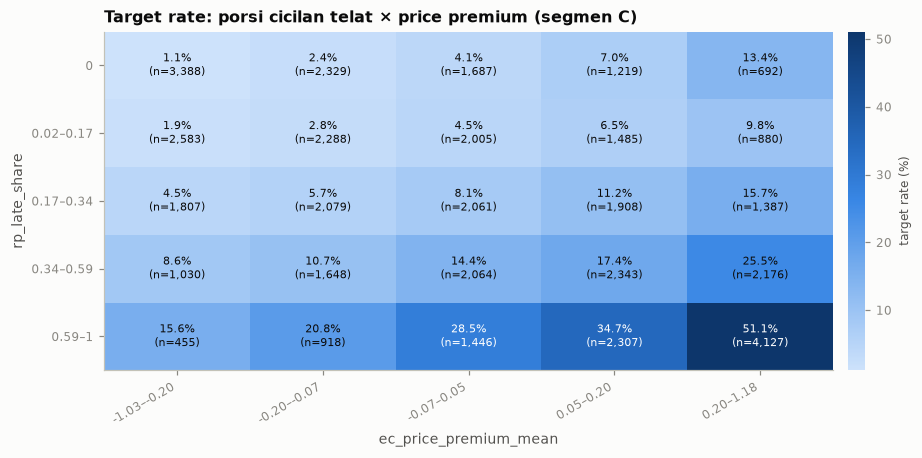

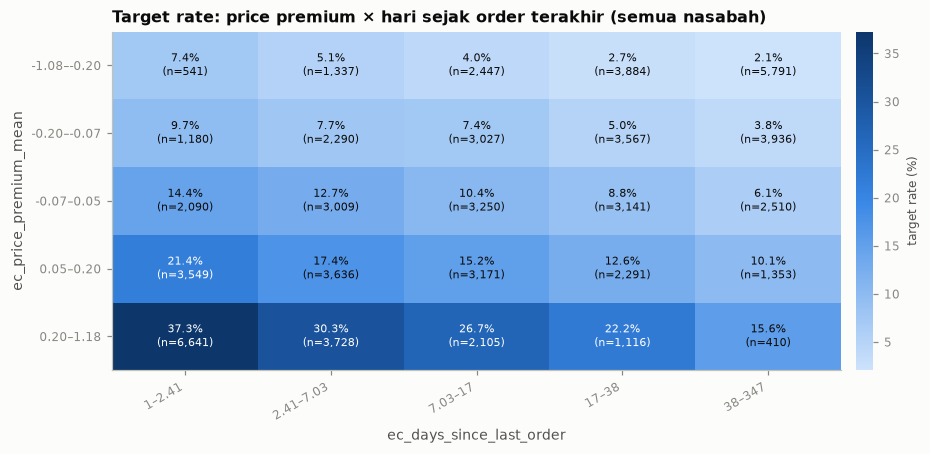

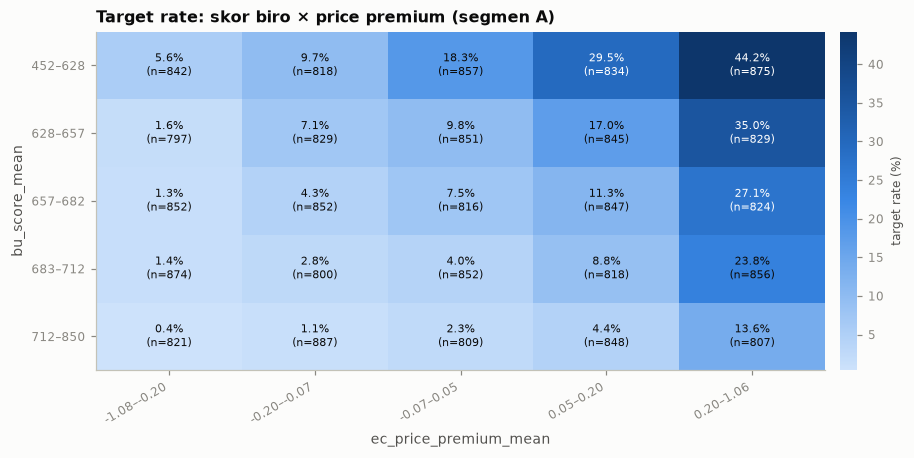

In [7]:
c6 = df.filter(pl.col("rp_late_share").is_not_null())
E.heatmap_rate(c6, "rp_late_share", "ec_price_premium_mean", row_bins=5, col_bins=5,
               title="Target rate: porsi cicilan telat × price premium (segmen C)", figsize=(9, 4))
E.heatmap_rate(df, "ec_price_premium_mean", "ec_days_since_last_order", row_bins=5, col_bins=5,
               title="Target rate: price premium × hari sejak order terakhir (semua nasabah)", figsize=(9, 4))
E.heatmap_rate(df.filter(pl.col("segment").str.starts_with("A")), "bu_score_mean", "ec_price_premium_mean", row_bins=5, col_bins=5,
               title="Target rate: skor biro × price premium (segmen A)", figsize=(9, 4))

**Jawaban Q6 — sinyal dari sumber berbeda saling MEMPERKUAT.**
- **Porsi telat × price premium (segmen C)**: dari ~1,5% (tidak pernah telat, harga murah) sampai ~50% (sering telat, harga mahal). Di setiap baris dan kolom, kedua fitur tetap monoton.
- **Price premium × keterbaruan belanja (semua nasabah)**: ~2,6% (murah, belanja terakhir > 2 bulan lalu) vs ~37% (mahal, belanja dalam 4 hari terakhir).
- **Skor biro × price premium (segmen A)**: ~0,4% vs ~42%. Untuk nasabah tanpa riwayat, kombinasi biro + e-commerce memberi rentang risiko ~100×.
- Efeknya terlihat **aditif/multiplikatif yang rapi** (tanpa pola aneh), sehingga GBDT bisa menangkapnya sendiri. Fitur interaksi manual tidak wajib, tapi rasio/perkalian sederhana bisa membantu model linear atau ensemble.

## Q7 · Stabilitas validasi & noise leaderboard

In [8]:
fold_rows = []
oofs_seed = {42: OOF["5. + e-commerce (LENGKAP)"]}
for seed in (7, 2024):
    _, oofs_seed[seed], _ = run(FULL, seed=seed)
for seed, oof in oofs_seed.items():
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)
    for k, (_, va) in enumerate(skf.split(np.zeros(len(y)), y)):
        fold_rows.append(dict(seed=seed, fold=k + 1, ks=E.ks_stat(y[va], oof[va])))
folds = pl.DataFrame(fold_rows)
summary = (folds.group_by("seed").agg(mean_fold=pl.col("ks").mean().round(4), sd_fold=pl.col("ks").std().round(4),
                                     min_fold=pl.col("ks").min().round(4), max_fold=pl.col("ks").max().round(4)).sort("seed"))
summary = summary.with_columns(pl.Series("ks_oof_total", [round(E.ks_stat(y, oofs_seed[s_]), 4) for s_ in summary["seed"].to_list()]))
display(summary)
blend = np.mean([np.argsort(np.argsort(o)) for o in oofs_seed.values()], axis=0)
print(f"KS rata-rata rank 3 seed (ensemble sederhana): {E.ks_stat(y, blend):.4f}")
rng = np.random.default_rng(0)
oof = oofs_seed[42]
for n in (9_000, 21_000, 30_000):
    v = [E.ks_stat(y[i], oof[i]) for i in (rng.choice(len(y), n, replace=False) for _ in range(300))]
    print(f"Simulasi leaderboard dengan {n:,} baris: SD KS ≈ {np.std(v):.4f}  (rentang 90%: {np.quantile(v, .05):.3f}–{np.quantile(v, .95):.3f})")

seed,mean_fold,sd_fold,min_fold,max_fold,ks_oof_total
i64,f64,f64,f64,f64,f64
7,0.5199,0.0066,0.5105,0.5282,0.5172
42,0.5198,0.0115,0.5086,0.5363,0.5162
2024,0.5198,0.0123,0.5006,0.5307,0.5147


KS rata-rata rank 3 seed (ensemble sederhana): 0.5186
Simulasi leaderboard dengan 9,000 baris: SD KS ≈ 0.0121  (rentang 90%: 0.501–0.541)
Simulasi leaderboard dengan 21,000 baris: SD KS ≈ 0.0067  (rentang 90%: 0.506–0.529)
Simulasi leaderboard dengan 30,000 baris: SD KS ≈ 0.0050  (rentang 90%: 0.510–0.526)


## Q8 · Rencana untuk Feature Engineering & Modeling

### Peta temuan EDA

| Sumber | Inti temuan | Kontribusi unik |
|---|---|---|
| Aplikasi & profil | Hanya suku bunga yang kuat, dan bunga = versi kasar skor biro. Profil & waktu ≈ noise | ≈ 0 |
| Riwayat internal | **Porsi cicilan telat** (0,44) untuk 66% nasabah; seluruh riwayat > jendela pendek; tunggakan aktif menambah sedikit | −0,046 |
| Biro | Skor rata-rata provider (0,25); inquiry/menunggak berisik → rata-rata semua laporan | −0,014 |
| Rekening | Hanya lonjakan pengeluaran menjelang pengajuan; tumpang tindih dengan e-commerce | ≈ 0 |
| E-commerce | **Price premium** (0,34) + lonjakan & keterbaruan belanja (0,26); tersedia 100% | −0,080 |

### Prioritas fitur

**Tier 1, inti** (sudah ada di `features.py`):
- Repayment: `rp_late_share`, `rp_mean_dpd`, `rp_max_dpd_ever`, `rp_paid_ratio`, `rp_n_inst`, `rp_current_dpd`, `rp_late_share_365d`
- E-commerce: `ec_price_premium_mean/median/base/30d`, `ec_days_since_last_order`, `ec_n_30d`, `ec_spend_14d/30d/90d`, `ec_order_surge_30d`, `ec_n_base`, `ec_aov_*`
- Biro: `bu_score_mean/min/max`, `bu_all_score_mean`, `bu_all_delinq_mean`, `bu_all_inq_mean`, `bu_outstanding_max`, `bu_util_mean`
- Beban: `dti`, `total_dti`, `ln_remaining_amount`, plus `annual_interest_rate` & `loan_amount`
- Flag `segment`

**Tier 2, berguna & murah**: `pa_last_rate`, `rate_change_vs_last`, `pa_n_365d`, `pa_days_since_last`, `ln_days_since_last_loan`, `ec_pay_share_COD`, 5 fitur lonjakan rekening, `bu_active_max`.

**Tier 3, jangan diinvestasikan / buang**: fitur kalender & lama proses, `loan_purpose`, pembatalan e-commerce, porsi kategori (sudah diwakili price premium), level saldo rekening, jumlah laporan/umur laporan biro, tren skor biro, `pa_cancel_*`, salah satu dari tiap pasangan |ρ| > 0,95.

### Ide fitur baru untuk diuji (urut prioritas)
1. **Price premium lanjutan**: dispersi (SD) premium, premium per kategori, premium tertimbang nilai item, tren premium (30 hari − baseline), dan premium pada order COD vs non-COD.
2. **Ritme belanja**: rata-rata jarak antar order di masa normal vs hari sejak order terakhir ("lebih cepat dari biasanya?"), jumlah hari aktif belanja dalam 30 hari, dan belanja 7/14 hari ÷ baseline.
3. **Repayment per pinjaman**: porsi telat pinjaman terburuk & pertama, jumlah siklus terlewat (Σ max_dpd ÷ 30), porsi telat tertimbang waktu.
4. **Lintas sumber**: belanja 30 hari ÷ pendapatan; total beban (cicilan baru + cicilan lama + proksi cicilan dari utang biro) ÷ pendapatan.
5. **Biro**: rata-rata inquiry/menunggak tertimbang waktu (laporan terbaru diberi bobot lebih).

### Checklist kebocoran & konsistensi
- [ ] Semua fitur dihitung relatif terhadap `decision_datetime` per nasabah (fungsi di `features.py` sudah begitu).
- [ ] Filter `< cutoff` dan `available_datetime ≤ cutoff` tetap ada di kode, sebagai pertahanan berlapis walau data sudah bersih.
- [ ] Median harga kategori = konstanta global **tanpa target**, dihitung sekali dari tabel e-commerce **penuh**, sama untuk train & test.
- [ ] Fitur train & test dihitung dari file yang **sama** (e-commerce penuh).
- [ ] Target encoding (bila dipakai) hanya **out-of-fold**.
- [ ] Seleksi fitur & tuning diputuskan dengan CV multi-seed, **bukan** public leaderboard.

### Rencana validasi & modeling
- **CV**: StratifiedKFold 5-fold × 3 seed; metrik utama = KS OOF rata-rata seed, plus KS per segmen.
- **Ambang perbaikan**: ≥ ~0,005 dan konsisten di semua seed.
- **Model**: LightGBM sebagai baseline (patokan EDA ~0,51 dengan data sampling, ~0,52 dengan data penuh), lalu CatBoost & XGBoost untuk ensemble (rank-average, dinormalisasi ke [0,1]).
- **Urutan kerja**: (1) bangun tabel fitur train+test dari `features.py` → (2) baseline LightGBM + submission pertama → (3) uji ide fitur baru satu per satu dengan CV multi-seed → (4) tuning → (5) ensemble.

---
**Ringkasan EDA dalam satu kalimat**: risiko gagal bayar di dataset ini paling baik diprediksi oleh **kebiasaan telat bayar** (bila ada riwayat) dan **perilaku belanja online**, terutama membayar lebih mahal per barang dan lonjakan belanja menjelang pengajuan. Skor biro (yang menentukan suku bunga) hanya pelengkap, dan profil demografi hampir tidak berguna.